<div align="center">

# TP4 - Projeto de Bloco: Análise e Segurança de Agentes de IA

</div>

##### Professor: Tiago Xavier;
###### Estudantes - E-mails:
###### Caio Ribeiro Pereira - caio.rpereira@al.infnet.edu.br;
###### Paulo Henrique de Paula Dias - paulo.dias@al.infnet.edu.br;
###### Pedro Marchiori de Araújo - pedro.maraujo@al.infnet.edu.br.

### Instruções

**Dataset**

O dataset utilizado é o *Customer Support Ticket Dataset*, disponível no Kaggle: https://www.kaggle.com/datasets/suraj520/customer-support-ticket-dataset/data

#### Tarefa

Treine o classificador de intenções com Scikit-learn usando o pipeline definido no TP3 (TF-IDF + LogisticRegression ou SVM). Avalie com matriz de confusão, precision, recall, F1-score por classe e ROC-AUC. Documente o desempenho e compare com uma baseline simples (ex: classificar sempre a classe mais frequente).

## 1. Variável de entrada, variável alvo e classes

A formalização do problema foi feita no TP3 (seção 8): **$X$** é o texto de `Ticket Description` e **$y$** é a coluna `Ticket Type`, com 5 classes (`Refund request`, `Technical issue`, `Cancellation request`, `Product inquiry`, `Billing inquiry`), razoavelmente equilibradas (entre ~19% e ~21% cada). Este notebook reaproveita essa definição, sem redefini-la.

In [12]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

cs_df = pd.read_csv("../data/customer_support_tickets.csv")
X = cs_df["Ticket Description"].fillna("")
y = cs_df["Ticket Type"]

print(f"Total de registros: {len(cs_df)}")
print(f"Classes: {sorted(y.unique())}")

Total de registros: 8469
Classes: ['Billing inquiry', 'Cancellation request', 'Product inquiry', 'Refund request', 'Technical issue']


## 2. Divisão treino/teste (estratificada)

In [13]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Treino: {X_treino.shape[0]} registros | Teste: {X_teste.shape[0]} registros")
print("Distribuição no teste (%):")
print((y_teste.value_counts(normalize=True) * 100).round(2))

Treino: 6775 registros | Teste: 1694 registros
Distribuição no teste (%):
Ticket Type
Refund request          20.72
Technical issue         20.60
Cancellation request    20.01
Product inquiry         19.36
Billing inquiry         19.30
Name: proportion, dtype: float64


## 3. Baseline simples

A baseline é um `DummyClassifier(strategy="most_frequent")`: ele sempre prevê a classe mais frequente do treino (`Refund request`), ignorando o texto. Serve como piso de comparação: qualquer modelo real precisa superar isso para justificar sua complexidade.

In [14]:
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_treino, y_treino)

y_pred_baseline = baseline.predict(X_teste)
y_proba_baseline = baseline.predict_proba(X_teste)

print("=== Baseline (most_frequent) ===")
print(classification_report(y_teste, y_pred_baseline, zero_division=0))

auc_baseline = roc_auc_score(y_teste, y_proba_baseline, multi_class="ovr", average="macro")
print(f"ROC-AUC (one-vs-rest, macro): {auc_baseline:.4f}")

=== Baseline (most_frequent) ===
                      precision    recall  f1-score   support

     Billing inquiry       0.00      0.00      0.00       327
Cancellation request       0.00      0.00      0.00       339
     Product inquiry       0.00      0.00      0.00       328
      Refund request       0.21      1.00      0.34       351
     Technical issue       0.00      0.00      0.00       349

            accuracy                           0.21      1694
           macro avg       0.04      0.20      0.07      1694
        weighted avg       0.04      0.21      0.07      1694

ROC-AUC (one-vs-rest, macro): 0.5000


## 4. Modelo: TF-IDF + Regressão Logística

Mantemos a Regressão Logística escolhida e justificada no `others/planejamento_tp3.md` (principalmente por fornecer `predict_proba` nativamente, necessário para o campo `confidence` da API). A técnica de representação de texto usada aqui é o TF-IDF, conforme pedido nesta etapa (`TfidfVectorizer`), em vez do `CountVectorizer` considerado no planejamento.

In [15]:
modelo = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", min_df=2, max_df=0.9)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

modelo.fit(X_treino, y_treino)

print(f"Tamanho do vocabulário TF-IDF: {len(modelo.named_steps['tfidf'].vocabulary_)}")

Tamanho do vocabulário TF-IDF: 2497


## 5. Avaliação do modelo

In [16]:
y_pred = modelo.predict(X_teste)
y_proba = modelo.predict_proba(X_teste)

print("=== Modelo (TF-IDF + LogisticRegression) ===")
print(classification_report(y_teste, y_pred, zero_division=0))

auc_macro = roc_auc_score(y_teste, y_proba, multi_class="ovr", average="macro")
auc_weighted = roc_auc_score(y_teste, y_proba, multi_class="ovr", average="weighted")
print(f"ROC-AUC (one-vs-rest, macro): {auc_macro:.4f}")
print(f"ROC-AUC (one-vs-rest, weighted): {auc_weighted:.4f}")

=== Modelo (TF-IDF + LogisticRegression) ===
                      precision    recall  f1-score   support

     Billing inquiry       0.19      0.19      0.19       327
Cancellation request       0.21      0.21      0.21       339
     Product inquiry       0.21      0.22      0.22       328
      Refund request       0.20      0.19      0.19       351
     Technical issue       0.21      0.21      0.21       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694

ROC-AUC (one-vs-rest, macro): 0.4987
ROC-AUC (one-vs-rest, weighted): 0.4985


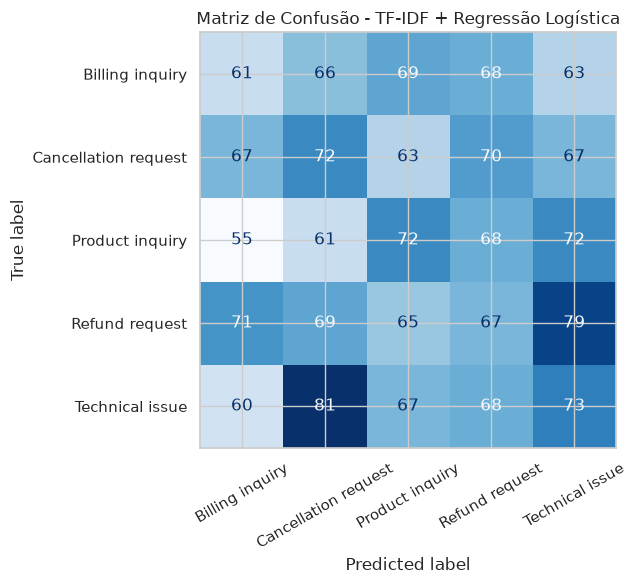

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred, labels=modelo.classes_, xticks_rotation=30, ax=ax, colorbar=False, cmap="Blues"
)
ax.set_title("Matriz de Confusão - TF-IDF + Regressão Logística")
plt.tight_layout()
plt.show()

## 6. Comparação com a baseline

| Métrica | Baseline (most_frequent) | Modelo (TF-IDF + LogReg) |
| --- | --- | --- |
| Acurácia | 0,2072 | 0,2037 |
| F1-score macro | 0,07 | 0,20 |
| ROC-AUC (OvR, macro) | 0,5000 | 0,4987 |

O modelo não supera a baseline. A acurácia global é, na prática, igual (ambas em torno de 20%, que é o esperado para 5 classes quase equilibradas por puro acaso). O F1-score macro do modelo é maior porque ele distribui previsões entre as 5 classes (a baseline tem F1 = 0 em 4 delas, por nunca prevê-las), mas o ROC-AUC do modelo fica em 0,4987 — estatisticamente igual a 0,5, ou seja, equivalente a chance (adivinhação aleatória). Isso indica que o TF-IDF sobre `Ticket Description` não carrega nenhum sinal preditivo real sobre `Ticket Type` neste dataset.

Esse resultado é consistente com o que já havia sido identificado na análise exploratória do TP2: as variáveis do dataset se comportam de forma estatisticamente independente entre si, um padrão compatível com dados gerados/balanceados artificialmente. O texto de `Ticket Description` aparentemente foi gerado sem relação causal real com o `Ticket Type` do mesmo registro.

## 7. Otimização de hiperparâmetros com GridSearchCV

Para otimizar o pipeline sem contaminar o conjunto de teste, a busca é executada **somente no conjunto de treino**. Utilizamos validação cruzada estratificada com 5 folds e `f1_macro` como métrica principal, adequada ao problema multiclasse por atribuir o mesmo peso a todas as intenções.

Foram avaliados dois hiperparâmetros, cada um com três valores:

- `clf__C`: `[0.1, 1.0, 10.0]`, controlando a regularização da Regressão Logística;
- `tfidf__ngram_range`: `[(1, 1), (1, 2), (1, 3)]`, avaliando unigramas, unigramas+bigramas e unigramas+bigramas+trigramas.

Isso resulta em 9 combinações e 45 ajustes ao considerar os 5 folds. O conjunto de teste permanece reservado para uma única avaliação final do melhor estimador.


In [18]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "clf__C": [0.1, 1.0, 10.0],
}

cv_estratificada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_estratificada,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

grid_search.fit(X_treino, y_treino)
melhor_modelo = grid_search.best_estimator_

print(f"Melhores parâmetros: {grid_search.best_params_}")
print(f"Melhor F1-macro médio na validação cruzada: {grid_search.best_score_:.6f}")


Fitting 5 folds for each of 9 candidates, totalling 45 fits
Melhores parâmetros: {'clf__C': 10.0, 'tfidf__ngram_range': (1, 2)}
Melhor F1-macro médio na validação cruzada: 0.210422


### Resultados de todas as combinações

In [19]:
resultados_grid = (
    pd.DataFrame(grid_search.cv_results_)[
        [
            "param_clf__C",
            "param_tfidf__ngram_range",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

resultados_grid


,param_clf__C,param_tfidf__ngram_range,mean_test_score,std_test_score,rank_test_score
0,10.0,"(1, 2)",0.210422,0.005606,1
1,10.0,"(1, 3)",0.209629,0.009033,2
2,10.0,"(1, 1)",0.203476,0.002463,3
3,1.0,"(1, 1)",0.200181,0.009011,4
4,1.0,"(1, 3)",0.196075,0.011925,5
5,0.1,"(1, 3)",0.195011,0.012744,6
6,1.0,"(1, 2)",0.193871,0.010694,7
7,0.1,"(1, 1)",0.190074,0.015507,8
8,0.1,"(1, 2)",0.188691,0.013588,9


### Avaliação final do melhor estimador no conjunto de teste

In [20]:
y_pred_otimizado = melhor_modelo.predict(X_teste)
y_proba_otimizado = melhor_modelo.predict_proba(X_teste)

accuracy_padrao = accuracy_score(y_teste, y_pred)
f1_padrao = f1_score(y_teste, y_pred, average="macro")

accuracy_otimizado = accuracy_score(y_teste, y_pred_otimizado)
f1_otimizado = f1_score(y_teste, y_pred_otimizado, average="macro")
auc_otimizado = roc_auc_score(
    y_teste,
    y_proba_otimizado,
    multi_class="ovr",
    average="macro",
)

print("Melhor modelo encontrado pelo GridSearchCV")
print(classification_report(y_teste, y_pred_otimizado, zero_division=0))
print(f"Acurácia: {accuracy_otimizado:.6f}")
print(f"F1-score macro: {f1_otimizado:.6f}")
print(f"ROC-AUC (one-vs-rest, macro): {auc_otimizado:.6f}")


Melhor modelo encontrado pelo GridSearchCV
                      precision    recall  f1-score   support

     Billing inquiry       0.23      0.23      0.23       327
Cancellation request       0.21      0.21      0.21       339
     Product inquiry       0.21      0.20      0.20       328
      Refund request       0.19      0.19      0.19       351
     Technical issue       0.21      0.22      0.22       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694

Acurácia: 0.208383
F1-score macro: 0.208483
ROC-AUC (one-vs-rest, macro): 0.501809


In [21]:
comparacao_otimizacao = pd.DataFrame(
    {
        "Métrica": ["Acurácia", "F1-score macro", "ROC-AUC macro"],
        "Modelo padrão": [accuracy_padrao, f1_padrao, auc_macro],
        "Modelo otimizado": [accuracy_otimizado, f1_otimizado, auc_otimizado],
    }
)
comparacao_otimizacao["Ganho absoluto"] = (
    comparacao_otimizacao["Modelo otimizado"]
    - comparacao_otimizacao["Modelo padrão"]
)
comparacao_otimizacao["Ganho relativo (%)"] = (
    comparacao_otimizacao["Ganho absoluto"]
    / comparacao_otimizacao["Modelo padrão"]
    * 100
)

comparacao_otimizacao.round(6)


,Métrica,Modelo padrão,Modelo otimizado,Ganho absoluto,Ganho relativo (%)
0,Acurácia,0.203660,0.208383,0.004723,2.318841
1,F1-score macro,0.203564,0.208483,0.004919,2.416625
2,ROC-AUC macro,0.498738,0.501809,0.003070,0.615624


### Melhores parâmetros e ganho de desempenho

O `GridSearchCV` selecionou `clf__C=10.0` e `tfidf__ngram_range=(1, 2)`. Em comparação ao pipeline padrão, no conjunto de teste:

| Métrica | Modelo padrão | Modelo otimizado | Ganho absoluto | Ganho relativo |
| --- | ---: | ---: | ---: | ---: |
| Acurácia | 0,203660 | 0,208383 | +0,004723 | +2,32% |
| F1-score macro | 0,203564 | 0,208483 | +0,004919 | +2,42% |
| ROC-AUC macro | 0,498738 | 0,501809 | +0,003071 | +0,62% |

Houve um ganho pequeno nas três métricas, com o F1-score macro aumentando aproximadamente 0,49 ponto percentual. Ainda assim, ROC-AUC de 0,501809 permanece essencialmente equivalente ao acaso. Portanto, a otimização encontra a melhor configuração dentro da grade proposta, mas não resolve a ausência de sinal preditivo forte entre `Ticket Description` e `Ticket Type` neste dataset.


## 8. Salvando o melhor modelo

O melhor estimador encontrado pelo `GridSearchCV` é salvo para uso pelo endpoint `/classify` da API. O artefato contém o pipeline completo, incluindo TF-IDF e Regressão Logística.

In [22]:
os.makedirs("../fastapi/ml", exist_ok=True)
caminho_modelo = "../fastapi/ml/intent_classifier.joblib"
joblib.dump(melhor_modelo, caminho_modelo)
print(f"Melhor modelo salvo em: {caminho_modelo}")

Melhor modelo salvo em: ../fastapi/ml/intent_classifier.joblib


## 9. Conclusão

O classificador `TF-IDF + Regressão Logística` foi treinado e avaliado com divisão estratificada treino/teste, matriz de confusão, `classification_report` (precision, recall e F1-score por classe) e ROC-AUC one-vs-rest. Comparado a uma baseline que sempre prevê a classe mais frequente, o modelo não apresenta ganho real: o ROC-AUC (0,4987) é equivalente ao de um classificador aleatório (0,5), e a acurácia global é praticamente a mesma da baseline.

Isso não é uma falha de implementação, mas um resultado honesto sobre os dados: `Ticket Description` não tem relação detectável com `Ticket Type` neste dataset, o que já era esperado a partir da análise de independência entre variáveis feita no TP2. O GridSearchCV avaliou 9 combinações de hiperparâmetros com validação cruzada estratificada de 5 folds. A melhor configuração (`C=10.0` e unigramas+bigramas) produziu ganho pequeno de 2,42% no F1-score macro, passando de 0,203564 para 0,208483. O melhor pipeline foi serializado para uso no endpoint `/classify`. Apesar do ganho, o ROC-AUC de 0,501809 continua próximo do acaso; esse resultado deve ser considerado como uma limitação conhecida do dataset sintético usado, e não como evidência de um classificador com boa capacidade preditiva.